# LM33 Lab — The Statistics of the Sharpe Ratio

Companion notebook to **From Calculus to Kelly, LM33**. It rebuilds the module's exhibits and computational examples from the through case's eight net wealth paths and from TR23, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Data: $R_t$, $x_t$, $T$, $A_{\mathrm w}$, the 90 calendar months and TR23; a check against the module's Sharpe ratios |
| 2 | (20.9) for the eight rules: Exhibit 1 (a), Exhibit 2, Example 1, Example 2; `scipy.stats` with every option passed; the illustrative $r_f$ |
| 3 | (33.1) by hand: Exhibit 3, Example 3, Example 4, problem 11 (b) |
| 4 | Lo's correction on 90 months: Example 5, the AR(1) check, problem 10 |
| 5 | PSR and MinTRL: Exhibit 4, Example 6, Bailey and López de Prado's 2012 example |
| 6 | Ledoit and Wolf's test by hand: experiment 1, Exhibit 1 (b), Exhibit 5, Example 7, problem 12, experiment 3 |
| 7 | The expected maximum (33.4) by quadrature, experiment 2, Exhibit 6, Example 8, the 2014 example, problem 8 (b) |
| 8 | Haircuts: Exhibit 7, Example 9, Harvey and Liu's example |
| 9 | Extension: R2's PSR(0) on rolling windows (a stability check) |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

On FinMind's free plan, run `uv run python data/fetch_finmind.py --exclude sectors_close/ --exclude vol4_settlement/ --exclude vol6/etf_snapshot` instead, as the book's Getting Started page says. This lab needs none of the excluded files.

`data/` then holds two files, and the notebook reads nothing outside `data/`:

- `rule_wealth_net.csv`: the through case's eight rules (`data/vol5_rules.py`), their net wealth after each day's trade (`rule`, `date`, `wealth`), on every session of E5's wealth frame from the first trade, 4 March 2019, to 8 October 2026.
- `taiex_tr.csv`: TR23, the TAIEX total-return index as FinMind's `TaiwanStockTotalReturnIndex` serves it (`date`, `price`), 2 January 2003 to 8 October 2026. Its dates are the wealth frame's calendar.

**Conventions (as in the module).**

- A rule's daily net return is $R_t=W_t/W_{t-1}-1$ from the session after the first trade, and its excess return $x_t=R_t-r_f/A_{\mathrm w}$, with the illustrative $r_f=1.5\%$ and $A_{\mathrm w}$ the wealth frame's sessions a year (every TR23 session after the base close of 17 January 2017, over the calendar years from it).
- Means, standard deviations, skewness and raw kurtosis divide by $T$ (normal kurtosis 3). Sharpe ratios are per observation in formulas and annualized by $\sqrt{A_{\mathrm w}}$, $\sqrt{12}$ or TR23's $\sqrt A$ for printing.
- The HAC lag is $\lfloor4(T/100)^{2/9}\rfloor$; the bootstrap block size is $b=22$; PSR, MinTRL and DSR use $\sqrt{T-1}$; intervals are $\pm1.959964$ standard errors.
- Experiments create `np.random.default_rng([e, 20261011])` once: $e=1$ the seven Ledoit–Wolf tests, $e=2$ the correlated maximum, $e=3$ the block sizes. Counts against a statistic use the guard `1e-12`; quantiles use `method="inverted_cdf"`.

In [1]:
import math
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from arch.bootstrap import optimal_block_length
from scipy import integrate, optimize, stats

DATA = Path("data")
RULES = ["R1", "R2", "R3", "R4", "R5", "R6", "R7", "R8"]
RF, SEED, EULER = 0.015, 20261011, 0.5772156649015329
Z95, Z975 = float(stats.norm.ppf(0.95)), 1.959964
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def show(label, value, fmt, printed):
    # print a value next to the module's printed value and assert that they agree
    got = format(value, fmt)
    print(f"{label}: {got}   [book: {printed}]")
    assert got == printed, (label, got, printed)


def show_row(label, got, printed):
    # a table row of the module, rebuilt; the module writes minus signs as U+2212
    got = got.replace("-", "−")
    print(f"{label}: {got}")
    assert got == printed, (label, got, printed)


def moments(x):
    # mean, s, sample skewness and raw kurtosis, all with divisor T, (19.3)
    m, s = float(x.mean()), float(x.std(ddof=0))
    c = x - m
    return m, s, float((c**3).mean() / s**3), float((c**4).mean() / s**4)


def v209(sr, sk, ku):
    # (20.9): T Var(SR hat) for iid returns
    return 1 - sr * sk + (ku - 1) / 4 * sr**2


def lag_rule(n):
    return math.floor(4 * (n / 100) ** (2 / 9))


def lrv(V, lag):
    # (23.7)'s Bartlett estimate of the long-run covariance of the centred rows of V, divisor T
    n = V.shape[0]
    S = V.T @ V / n
    for k in range(1, lag + 1):
        G = V[k:].T @ V[:-k] / n
        S = S + (1 - k / (lag + 1)) * (G + G.T)
    return S


def se_sr_hac(x, lag):
    # (33.1): the delta method with the long-run covariance of (x - mean, (x - mean)^2 - s^2)
    m, s, _, _ = moments(x)
    c = x - m
    g = np.array([1 / s, -m / (2 * s**3)])
    return float(np.sqrt(g @ lrv(np.column_stack([c, c**2 - s**2]), lag) @ g / len(x)))


def se_mean_hac(x, lag):
    c = (x - x.mean())[:, None]
    return float(np.sqrt(lrv(c, lag)[0, 0] / len(x)))


def se_vol_hac(x, lag):
    # the SE of s: (x - mean)^2 has a long-run variance; ds / d(s^2) = 1 / (2 s)
    m, s, _, _ = moments(x)
    c = ((x - m) ** 2 - s**2)[:, None]
    return float(np.sqrt(lrv(c, lag)[0, 0] / len(x)) / (2 * s))


def psr(sr, sr0, n_obs, sk, ku):
    # (33.2), with sqrt(T - 1)
    return float(stats.norm.cdf((sr - sr0) * math.sqrt(n_obs - 1) / math.sqrt(v209(sr, sk, ku))))


def mintrl(sr, sr0, sk, ku, conf=0.95):
    # (33.3), in observations
    return 1 + v209(sr, sk, ku) * (stats.norm.ppf(conf) / (sr - sr0)) ** 2


def emax(n):
    # (33.4): E Z_(n) by quadrature of the two integrals
    if n == 1:
        return 0.0
    up = integrate.quad(lambda z: 1 - stats.norm.cdf(z) ** n, 0, 12, limit=200, epsabs=1e-13, epsrel=1e-13)[0]
    lo = integrate.quad(lambda z: stats.norm.cdf(z) ** n, -12, 0, limit=200, epsabs=1e-13, epsrel=1e-13)[0]
    return up - lo


def emax_bldp(n):
    # Bailey and Lopez de Prado's (2014) approximation of E Z_(n)
    return float((1 - EULER) * stats.norm.ppf(1 - 1 / n) + EULER * stats.norm.ppf(1 - 1 / (n * math.e)))


def holm(p):
    # (21.7)'s adjusted p-values, in the input order
    order = sorted(range(len(p)), key=lambda i: p[i])
    adj, run = [0.0] * len(p), 0.0
    for r, i in enumerate(order):
        run = max(run, min(1.0, (len(p) - r) * p[i]))
        adj[i] = run
    return adj


def two_sided(t):
    return float(2 * stats.norm.sf(abs(t)))


def rho1(y):
    # (19.5)'s lag-1 autocorrelation, divisor T in both sums
    c = y - y.mean()
    return float(c[1:] @ c[:-1] / (c @ c))

## Part 1 — Data: the rules' returns, the months and TR23

The rules' wealth paths lie on the wealth frame's dates, every session. $A_{\mathrm w}$ comes from that frame's calendar, which is TR23's.

In [2]:
wl = pl.read_csv(DATA / "rule_wealth_net.csv", schema_overrides={"rule": pl.Utf8, "date": pl.Utf8})
Wd = wl.pivot(on="rule", index="date", values="wealth").sort("date").select("date", *RULES)
dates = Wd["date"].to_list()
WM = Wd.select(RULES).to_numpy()
tr = pl.read_csv(DATA / "taiex_tr.csv", schema_overrides={"date": pl.Utf8}).sort("date")
tr_dates = tr["date"].to_list()
assert dates == [d for d in tr_dates if dates[0] <= d <= dates[-1]], "the paths lie on every session"
frame = [d for d in tr_dates if "2017-01-17" < d <= "2026-10-08"]
years_w = (date(2026, 10, 8) - date(2017, 1, 17)).days / 365.25
Aw = len(frame) / years_w
R = WM[1:] / WM[:-1] - 1
assert (1 + R > 0).all(), "no rule is ruined, so every log below is defined"
X = R - RF / Aw
T = len(R)
sqA = math.sqrt(Aw)
tau = T / Aw
cal = (date.fromisoformat(dates[-1]) - date.fromisoformat(dates[0])).days / 365.25
L = lag_rule(T)
print(f"{T} daily net returns {dates[1]} .. {dates[-1]} (first trade {dates[0]})")
show("T", T, ",d", "1,851")
show("wealth frame sessions", len(frame), ",d", "2,368")
show("A_w", Aw, ".2f", "243.57")
show("years of sessions T / A_w", tau, ".4f", "7.5995")
show("calendar years from the first trade's close", cal, ".4f", "7.5975")
show("HAC lag", L, "d", "7")

ym = [d[:7] for d in dates]
ends = [i for i in range(len(dates)) if i == len(dates) - 1 or ym[i] != ym[i + 1]]
full = np.array([i for i in ends if "2019-03" <= ym[i] <= "2026-09"])
nsess = np.diff(full)
print(f"{len(full) - 1} calendar months {ym[full[1]]} .. {ym[full[-1]]}, {nsess.min()} to {nsess.max()} sessions; "
      f"excluded: {sum(d[:7] == '2019-03' for d in dates[1:])} returns of March 2019 and "
      f"{sum(d[:7] == '2026-10' for d in dates[1:])} of October 2026")

P = tr["price"].to_numpy().astype(float)
Rt = P[1:] / P[:-1] - 1                                  # TR23's simple returns, r_f = 0
Tt = len(Rt)
At = Tt / ((date.fromisoformat(tr_dates[-1]) - date.fromisoformat(tr_dates[0])).days / 365.25)
show("TR23 T", Tt, ",d", "5,849")
show("TR23 A", At, ".2f", "246.12")

mom = {k: moments(X[:, j]) for j, k in enumerate(RULES)}
SR = {k: mom[k][0] / mom[k][1] for k in RULES}
for k, p in zip(RULES, ["0.976", "1.138", "0.775", "0.629", "0.843", "0.955", "0.918", "0.935"]):
    show(f"{k}'s Sharpe ratio a year", SR[k] * sqA, ".3f", p)

1851 daily net returns 2019-03-05 .. 2026-10-08 (first trade 2019-03-04)
T: 1,851   [book: 1,851]
wealth frame sessions: 2,368   [book: 2,368]
A_w: 243.57   [book: 243.57]
years of sessions T / A_w: 7.5995   [book: 7.5995]
calendar years from the first trade's close: 7.5975   [book: 7.5975]
HAC lag: 7   [book: 7]
90 calendar months 2019-04 .. 2026-09, 12 to 23 sessions; excluded: 19 returns of March 2019 and 6 of October 2026
TR23 T: 5,849   [book: 5,849]
TR23 A: 246.12   [book: 246.12]
R1's Sharpe ratio a year: 0.976   [book: 0.976]
R2's Sharpe ratio a year: 1.138   [book: 1.138]
R3's Sharpe ratio a year: 0.775   [book: 0.775]
R4's Sharpe ratio a year: 0.629   [book: 0.629]
R5's Sharpe ratio a year: 0.843   [book: 0.843]
R6's Sharpe ratio a year: 0.955   [book: 0.955]
R7's Sharpe ratio a year: 0.918   [book: 0.918]
R8's Sharpe ratio a year: 0.935   [book: 0.935]


## Part 2 — The checkpoint: (20.9) for eight rules

Exhibit 1 (a), Exhibit 2, Example 1 and Example 2. SciPy's `skew` and `kurtosis` are called with every option that changes the number.

Exhibit 1 (a), R1: | R1 | 0.976 | 0.370 | 0.363 | 0.26 to 1.69 | 0.996 |
Exhibit 1 (a), R2: | R2 | 1.138 | 0.367 | 0.382 | 0.39 to 1.89 | 0.999 |
Exhibit 1 (a), R3: | R3 | 0.775 | 0.370 | 0.373 | 0.04 to 1.51 | 0.982 |
Exhibit 1 (a), R4: | R4 | 0.629 | 0.368 | 0.340 | −0.04 to 1.30 | 0.956 |
Exhibit 1 (a), R5: | R5 | 0.843 | 0.370 | 0.374 | 0.11 to 1.58 | 0.989 |
Exhibit 1 (a), R6: | R6 | 0.955 | 0.371 | 0.370 | 0.23 to 1.68 | 0.995 |
Exhibit 1 (a), R7: | R7 | 0.918 | 0.370 | 0.368 | 0.20 to 1.64 | 0.993 |
Exhibit 1 (a), R8: | R8 | 0.935 | 0.371 | 0.368 | 0.21 to 1.66 | 0.994 |
normal SE a year: ['0.363']


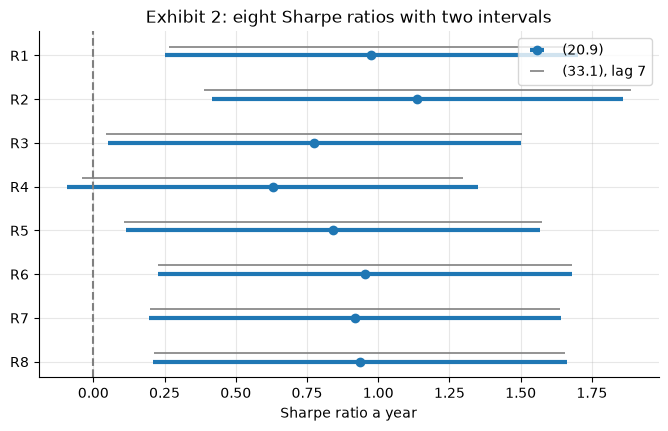

In [3]:
SE9 = {k: math.sqrt(v209(SR[k], mom[k][2], mom[k][3]) / T) for k in RULES}
SEN = {k: math.sqrt((1 + SR[k] ** 2 / 2) / T) for k in RULES}
SEH = {k: se_sr_hac(X[:, j], L) for j, k in enumerate(RULES)}
PSR0 = {k: psr(SR[k], 0, T, mom[k][2], mom[k][3]) for k in RULES}
CI9 = {k: ((SR[k] - Z975 * SE9[k]) * sqA, (SR[k] + Z975 * SE9[k]) * sqA) for k in RULES}
CIH = {k: ((SR[k] - Z975 * SEH[k]) * sqA, (SR[k] + Z975 * SEH[k]) * sqA) for k in RULES}
X1A = {
    "R1": "| R1 | 0.976 | 0.370 | 0.363 | 0.26 to 1.69 | 0.996 |",
    "R2": "| R2 | 1.138 | 0.367 | 0.382 | 0.39 to 1.89 | 0.999 |",
    "R3": "| R3 | 0.775 | 0.370 | 0.373 | 0.04 to 1.51 | 0.982 |",
    "R4": "| R4 | 0.629 | 0.368 | 0.340 | −0.04 to 1.30 | 0.956 |",
    "R5": "| R5 | 0.843 | 0.370 | 0.374 | 0.11 to 1.58 | 0.989 |",
    "R6": "| R6 | 0.955 | 0.371 | 0.370 | 0.23 to 1.68 | 0.995 |",
    "R7": "| R7 | 0.918 | 0.370 | 0.368 | 0.20 to 1.64 | 0.993 |",
    "R8": "| R8 | 0.935 | 0.371 | 0.368 | 0.21 to 1.66 | 0.994 |",
}
for k in RULES:
    got = (f"| {k} | {SR[k] * sqA:.3f} | {SE9[k] * sqA:.3f} | {SEH[k] * sqA:.3f} | {CIH[k][0]:.2f} to "
           f"{CIH[k][1]:.2f} | {PSR0[k]:.3f} |")
    show_row(f"Exhibit 1 (a), {k}", got, X1A[k])
print("normal SE a year:", sorted({f"{SEN[k] * sqA:.3f}" for k in RULES}))

fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(8, 0, -1)
ax.errorbar([SR[k] * sqA for k in RULES], y, xerr=[[SR[k] * sqA - CI9[k][0] for k in RULES],
            [CI9[k][1] - SR[k] * sqA for k in RULES]], fmt="o", capsize=0, lw=3, label="(20.9)")
ax.errorbar([SR[k] * sqA for k in RULES], y + 0.2, xerr=[[SR[k] * sqA - CIH[k][0] for k in RULES],
            [CIH[k][1] - SR[k] * sqA for k in RULES]], fmt="none", color="grey", lw=1.2, label="(33.1), lag 7")
ax.axvline(0, ls="--", color="grey")
ax.set_yticks(y, RULES)
ax.set_xlabel("Sharpe ratio a year")
ax.set_title("Exhibit 2: eight Sharpe ratios with two intervals")
ax.legend()
plt.show()

In [4]:
x2 = X[:, RULES.index("R2")]
m2, s2, sk2, ku2 = mom["R2"]
show("Example 1: mean excess (%)", 100 * m2, ".4f", "0.0564")
show("s (%)", 100 * s2, ".3f", "0.774")
show("skewness", sk2, ".3f", "-0.112")
show("raw kurtosis", ku2, ".2f", "13.58")
show("daily ratio", SR["R2"], ".4f", "0.0729")
show("skewness term", -SR["R2"] * sk2, ".4f", "0.0082")
show("kurtosis term", (ku2 - 1) / 4 * SR["R2"] ** 2, ".4f", "0.0167")
show("V", v209(SR["R2"], sk2, ku2), ".4f", "1.0249")
show("SE a day", SE9["R2"], ".4f", "0.0235")
show("SE a year", SE9["R2"] * sqA, ".3f", "0.367")
show("t-stat SR sqrt(T)", SR["R2"] * math.sqrt(T), ".2f", "3.14")

# SciPy with every option passed: bias=True is the divisor T of (19.3); fisher=False is the raw kurtosis
assert abs(stats.skew(x2, bias=True) - sk2) < 1e-12
assert abs(stats.kurtosis(x2, fisher=False, bias=True) - ku2) < 1e-10
show("scipy.stats.kurtosis with its defaults (excess)", float(stats.kurtosis(x2)), ".2f", "10.58")

rows = []
for k in RULES:
    m, s, sk, ku = mom[k]
    se_m, se_v = s / math.sqrt(T) * Aw, s * math.sqrt((ku - 1) / (4 * T)) * sqA
    rows.append(f"| {k} | {100 * m * Aw:.2f} ({100 * se_m:.2f}) | {100 * s * sqA:.2f} ({100 * se_v:.2f}) | "
                f"{sk:.2f} | {ku:.1f} |")
for r in rows:
    print(r.replace("-", "−"))
show_row("Example 2, R4", rows[3], "| R4 | 10.40 (6.00) | 16.53 (0.59) | −0.66 | 10.3 |")
show_row("Example 2, R8", rows[7], "| R8 | 10.77 (4.18) | 11.52 (0.63) | −0.42 | 23.0 |")

show("R4's (20.9) interval, low", CI9["R4"][0], ".2f", "-0.09")
show("R4's (20.9) interval, high", CI9["R4"][1], ".2f", "1.35")
show("R4's PSR(0)", PSR0["R4"], ".3f", "0.956")
hp = holm([1 - PSR0[k] for k in RULES])
print("Holm on the eight one-sided p-values: rejections", sum(a <= 0.05 + 1e-12 for a in hp))
show("largest adjusted p-value", max(hp), ".3f", "0.044")

for rate, lo_, hi_ in ((0.0, "0.09", "0.15"), (0.02, "0.03", "0.05")):
    mo = {k: moments(R[:, j] - rate / Aw) for j, k in enumerate(RULES)}
    chg = [abs(mo[k][0] / mo[k][1] - SR[k]) * sqA for k in RULES]
    show(f"r_f {rate:.0%}: smallest change", min(chg), ".2f", lo_)
    show(f"r_f {rate:.0%}: largest change", max(chg), ".2f", hi_)
    p1 = {k: psr(mo[k][0] / mo[k][1], 0, T, mo[k][2], mo[k][3]) for k in RULES}
    print(f"   best {max(p1, key=lambda k: mo[k][0] / mo[k][1])}, worst {min(RULES, key=lambda k: mo[k][0] / mo[k][1])}, "
          f"Holm rejections {sum(a <= 0.05 + 1e-12 for a in holm([1 - p1[k] for k in RULES]))}")
    if rate == 0.02:
        show("r_f 2%: R4's PSR(0)", p1["R4"], ".3f", "0.948")

Example 1: mean excess (%): 0.0564   [book: 0.0564]
s (%): 0.774   [book: 0.774]
skewness: -0.112   [book: -0.112]
raw kurtosis: 13.58   [book: 13.58]
daily ratio: 0.0729   [book: 0.0729]
skewness term: 0.0082   [book: 0.0082]
kurtosis term: 0.0167   [book: 0.0167]
V: 1.0249   [book: 1.0249]
SE a day: 0.0235   [book: 0.0235]
SE a year: 0.367   [book: 0.367]
t-stat SR sqrt(T): 3.14   [book: 3.14]
scipy.stats.kurtosis with its defaults (excess): 10.58   [book: 10.58]
| R1 | 12.19 (4.53) | 12.48 (0.58) | −0.39 | 16.8 |
| R2 | 13.74 (4.38) | 12.08 (0.50) | −0.11 | 13.6 |
| R3 | 7.71 (3.61) | 9.96 (0.45) | −0.61 | 16.2 |
| R4 | 10.40 (6.00) | 16.53 (0.59) | −0.66 | 10.3 |
| R5 | 8.40 (3.62) | 9.97 (0.45) | −0.60 | 16.1 |
| R6 | 9.86 (3.75) | 10.32 (0.48) | −0.49 | 17.1 |
| R7 | 9.31 (3.68) | 10.14 (0.42) | −0.47 | 14.0 |
| R8 | 10.77 (4.18) | 11.52 (0.63) | −0.42 | 23.0 |
Example 2, R4: | R4 | 10.40 (6.00) | 16.53 (0.59) | −0.66 | 10.3 |
Example 2, R8: | R8 | 10.77 (4.18) | 11.52 (0.63) | −

## Part 3 — The HAC standard error (33.1)

Exhibit 3, Example 3 and Example 4; problem 11 (b). At lag 0, (33.1) equals (20.9).

R1 ['0.370', '0.363', '0.359', '0.367']
R2 ['0.367', '0.382', '0.393', '0.389']
R4 ['0.368', '0.340', '0.316', '0.300']
problem 11 (b): R2 at lag 0: 0.367   [book: 0.367]
problem 11 (b): R2 at lag 7: 0.382   [book: 0.382]
problem 11 (b): R2 at lag 20: 0.393   [book: 0.393]
problem 11 (b): R2 at lag 60: 0.389   [book: 0.389]
HAC over (20.9), lowest (R4): 0.92   [book: 0.92]
HAC over (20.9), highest (R2): 1.04   [book: 1.04]
rho_1 of the daily excess returns: {'R1': -0.054, 'R2': -0.019, 'R3': -0.019, 'R4': 0.002, 'R5': -0.016, 'R6': -0.027, 'R7': -0.019, 'R8': -0.022}
rho_1 of R1's squared deviations: 0.246   [book: 0.246]
volatility: HAC over iid, lowest: 1.51   [book: 1.51]
volatility: HAC over iid, highest: 1.60   [book: 1.60]
R1's volatility SE, iid (%): 0.576   [book: 0.576]
R1's volatility SE, lag 7 (%): 0.872   [book: 0.872]
R1's volatility SE, lag 20 (%): 1.026   [book: 1.026]
R1's volatility SE, lag 60 (%): 1.156   [book: 1.156]
R1's mean: HAC over iid: 0.94   [book: 0.94]


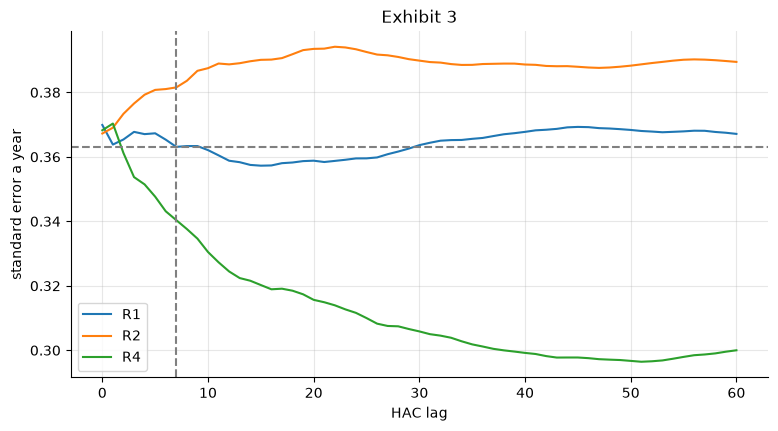

TR23 daily ratio: 0.05173   [book: 0.05173]
TR23 a year: 0.81   [book: 0.81]
TR23 skewness: -0.34   [book: -0.34]
TR23 raw kurtosis: 8.27   [book: 8.27]
TR23 (20.9) a year: 0.207   [book: 0.207]
TR23 (33.1), lag 9: 0.213   [book: 0.213]
TR23 (33.1), lag 145: 0.243   [book: 0.243]


In [5]:
for j, k in enumerate(RULES):
    assert abs(se_sr_hac(X[:, j], 0) - SE9[k]) < 1e-15
lags = range(61)
curve = {k: [se_sr_hac(X[:, RULES.index(k)], lg) * sqA for lg in lags] for k in ("R1", "R2", "R4")}
for k in ("R1", "R2", "R4"):
    print(k, [f"{curve[k][lg]:.3f}" for lg in (0, 7, 20, 60)])
for lg, p in zip((0, 7, 20, 60), ("0.367", "0.382", "0.393", "0.389")):
    show(f"problem 11 (b): R2 at lag {lg}", curve["R2"][lg], ".3f", p)
ratio = {k: SEH[k] / SE9[k] for k in RULES}
show("HAC over (20.9), lowest (R4)", min(ratio.values()), ".2f", "0.92")
show("HAC over (20.9), highest (R2)", max(ratio.values()), ".2f", "1.04")
print("rho_1 of the daily excess returns:", {k: round(rho1(X[:, j]), 3) for j, k in enumerate(RULES)})
x1 = X[:, 0]
show("rho_1 of R1's squared deviations", rho1((x1 - x1.mean()) ** 2), ".3f", "0.246")
vr = {k: se_vol_hac(X[:, j], L) / (mom[k][1] * math.sqrt((mom[k][3] - 1) / (4 * T))) for j, k in enumerate(RULES)}
show("volatility: HAC over iid, lowest", min(vr.values()), ".2f", "1.51")
show("volatility: HAC over iid, highest", max(vr.values()), ".2f", "1.60")
show("R1's volatility SE, iid (%)", 100 * mom["R1"][1] * math.sqrt((mom["R1"][3] - 1) / (4 * T)) * sqA, ".3f", "0.576")
for lg, p in zip((7, 20, 60), ("0.872", "1.026", "1.156")):
    show(f"R1's volatility SE, lag {lg} (%)", 100 * se_vol_hac(x1, lg) * sqA, ".3f", p)
show("R1's mean: HAC over iid", se_mean_hac(x1, L) / (mom["R1"][1] / math.sqrt(T)), ".2f", "0.94")

fig, ax = plt.subplots()
for k in ("R1", "R2", "R4"):
    ax.plot(list(lags), curve[k], label=k)
ax.axhline(0.363, ls="--", color="grey")
ax.axvline(7, ls="--", color="grey")
ax.set_xlabel("HAC lag")
ax.set_ylabel("standard error a year")
ax.set_title("Exhibit 3")
ax.legend()
plt.show()

mt, st, skt, kut = moments(Rt)
srt = mt / st
show("TR23 daily ratio", srt, ".5f", "0.05173")
show("TR23 a year", srt * math.sqrt(At), ".2f", "0.81")
show("TR23 skewness", skt, ".2f", "-0.34")
show("TR23 raw kurtosis", kut, ".2f", "8.27")
show("TR23 (20.9) a year", math.sqrt(v209(srt, skt, kut) / Tt) * math.sqrt(At), ".3f", "0.207")
show("TR23 (33.1), lag 9", se_sr_hac(Rt, lag_rule(Tt)) * math.sqrt(At), ".3f", "0.213")
show("TR23 (33.1), lag 145", se_sr_hac(Rt, 145) * math.sqrt(At), ".3f", "0.243")

## Part 4 — Lo's correction on 90 calendar months

Example 5 and problem 10: monthly log excess returns, (19.9) with $\hat\rho_1,\dots,\hat\rho_{11}$, and the robust standard error of the ratio by (25.6) with (25.4).

In [6]:
lo_rows = {}
for j, k in enumerate(RULES):
    w = WM[full, j]
    xm = np.log(w[1:] / w[:-1]) - nsess * np.log(1 + RF / Aw)
    c = xm - xm.mean()
    rho = [float(c[i:] @ c[:-i] / (c @ c)) for i in range(1, 12)]
    ratio12 = 1 + 2 * sum((1 - i / 12) * rho[i - 1] for i in range(1, 12))
    se_rob = math.sqrt(sum((2 * (1 - i / 12)) ** 2 * float(np.sum(c[i:] ** 2 * c[:-i] ** 2)) / float(c @ c) ** 2
                           for i in range(1, 12)))
    srm = float(xm.mean() / xm.std(ddof=0))
    lo_rows[k] = (srm, srm * math.sqrt(12), srm * math.sqrt(12 / ratio12), ratio12, se_rob, math.sqrt(12 / ratio12))
print(pl.DataFrame({"rule": RULES, "monthly SR": [round(lo_rows[k][0], 3) for k in RULES],
                    "x sqrt(12)": [round(lo_rows[k][1], 2) for k in RULES],
                    "(19.9)": [round(lo_rows[k][2], 2) for k in RULES],
                    "ratio": [round(lo_rows[k][3], 3) for k in RULES],
                    "robust SE": [round(lo_rows[k][4], 2) for k in RULES]}))
srm, a12, alo, rat, srob, _ = lo_rows["R1"]
show("problem 10: R1's monthly ratio", srm, ".3f", "0.305")
show("by sqrt(12)", a12, ".2f", "1.06")
show("by (19.9)", alo, ".2f", "0.92")
show("the ratio", rat, ".2f", "1.31")
show("its robust SE", srob, ".2f", "0.38")
se_iid = math.sqrt(2 * 23 * 11 / (3 * 12 * 90))
show("(25.6)'s iid SE", se_iid, ".3f", "0.395")
show("the excess over 1 in iid SEs", (rat - 1) / se_iid, ".2f", "0.78")
sf = [lo_rows[k][5] for k in RULES]
show("scale factors, lowest", min(sf), ".2f", "2.74")
show("scale factors, highest", max(sf), ".2f", "3.33")
ar = 12 / math.sqrt(12 + 2 * sum((12 - i) * 0.2**i for i in range(1, 12)))
show("AR(1) with rho_1 = 0.2: the scale factor", ar, ".3f", "2.879")
show("sqrt(12) over it", math.sqrt(12) / ar, ".3f", "1.203")
dl = {k: (np.log(1 + R[:, j]) - np.log(1 + RF / Aw)) for j, k in enumerate(RULES)}
dlr = {k: dl[k].mean() / dl[k].std(ddof=0) * sqA for k in RULES}
show("daily log ratios, lowest (R4)", min(dlr.values()), ".2f", "0.54")
show("daily log ratios, highest (R2)", max(dlr.values()), ".2f", "1.08")

shape: (8, 6)
┌──────┬────────────┬────────────┬────────┬───────┬───────────┐
│ rule ┆ monthly SR ┆ x sqrt(12) ┆ (19.9) ┆ ratio ┆ robust SE │
│ ---  ┆ ---        ┆ ---        ┆ ---    ┆ ---   ┆ ---       │
│ str  ┆ f64        ┆ f64        ┆ f64    ┆ f64   ┆ f64       │
╞══════╪════════════╪════════════╪════════╪═══════╪═══════════╡
│ R1   ┆ 0.305      ┆ 1.06       ┆ 0.92   ┆ 1.309 ┆ 0.38      │
│ R2   ┆ 0.304      ┆ 1.05       ┆ 0.94   ┆ 1.246 ┆ 0.44      │
│ R3   ┆ 0.225      ┆ 0.78       ┆ 0.75   ┆ 1.084 ┆ 0.39      │
│ R4   ┆ 0.18       ┆ 0.62       ┆ 0.49   ┆ 1.602 ┆ 0.48      │
│ R5   ┆ 0.246      ┆ 0.85       ┆ 0.8    ┆ 1.137 ┆ 0.39      │
│ R6   ┆ 0.298      ┆ 1.03       ┆ 0.92   ┆ 1.268 ┆ 0.39      │
│ R7   ┆ 0.283      ┆ 0.98       ┆ 0.92   ┆ 1.131 ┆ 0.4       │
│ R8   ┆ 0.287      ┆ 0.99       ┆ 0.92   ┆ 1.158 ┆ 0.37      │
└──────┴────────────┴────────────┴────────┴───────┴───────────┘
problem 10: R1's monthly ratio: 0.305   [book: 0.305]
by sqrt(12): 1.06   [book: 1.06]
by 

## Part 5 — PSR and the minimum track record

Exhibit 4 and Example 6, with Bailey and López de Prado's (2012) example from their appendix code's inputs.

R2: MinTRL against zero (sessions): 523   [book: 523]
R2: in years of sessions: 2.15   [book: 2.15]
R2: with normal moments: 2.10   [book: 2.10]
R1: MinTRL against zero (sessions): 720   [book: 720]
R1: in years of sessions: 2.96   [book: 2.96]
R1: with normal moments: 2.85   [book: 2.85]
R4: MinTRL against zero (sessions): 1,717   [book: 1,717]
R4: in years of sessions: 7.05   [book: 7.05]
R4: with normal moments: 6.85   [book: 6.85]
R2's z with sqrt(T - 1): 3.097   [book: 3.097]
with sqrt(T): 3.098   [book: 3.098]
TR23's PSR(0): 0.99995   [book: 0.99995]
TR23's MinTRL (sessions): 1,035   [book: 1,035]
in years of sessions: 4.20   [book: 4.20]
TR23 with normal moments, years of sessions: 4.12   [book: 4.12]
(21.4) one-sided at power 1/2: 4.11   [book: 4.11]
Bailey and Lopez de Prado (2012): months: 59.9   [book: 59.9]
normal months: 38.9   [book: 38.9]
years: 4.99   [book: 4.99]
normal years: 3.24   [book: 3.24]
annual SR 0.5: MinTRL 10.83 years of sessions; PSR(0) at 7.60 years of se

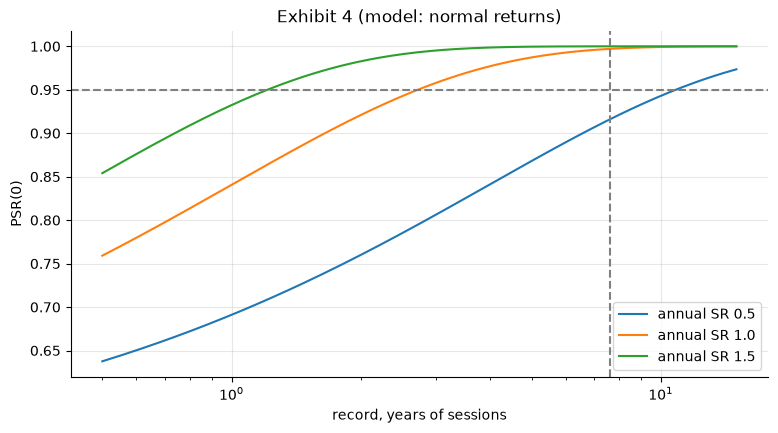

In [7]:
mt_rows = (("R2", "523", "2.15", "2.10"), ("R1", "720", "2.96", "2.85"),
           ("R4", "1,717", "7.05", "6.85"))
for k, n0, y0, yn in mt_rows:
    _, _, sk, ku = mom[k]
    n_ = mintrl(SR[k], 0, sk, ku)
    show(f"{k}: MinTRL against zero (sessions)", n_, ",.0f", n0)
    show(f"{k}: in years of sessions", n_ / Aw, ".2f", y0)
    show(f"{k}: with normal moments", mintrl(SR[k], 0, 0, 3) / Aw, ".2f", yn)
z1 = SR["R2"] * math.sqrt(T - 1) / math.sqrt(v209(SR["R2"], sk2, ku2))
show("R2's z with sqrt(T - 1)", z1, ".3f", "3.097")
show("with sqrt(T)", z1 * math.sqrt(T / (T - 1)), ".3f", "3.098")
show("TR23's PSR(0)", psr(srt, 0, Tt, skt, kut), ".5f", "0.99995")
n_tr = mintrl(srt, 0, skt, kut)
show("TR23's MinTRL (sessions)", n_tr, ",.0f", "1,035")
show("in years of sessions", n_tr / At, ".2f", "4.20")
show("TR23 with normal moments, years of sessions", mintrl(srt, 0, 0, 3) / At, ".2f", "4.12")
show("(21.4) one-sided at power 1/2", (Z95 / (srt * math.sqrt(At))) ** 2, ".2f", "4.11")
n12 = mintrl(2 / math.sqrt(12), 1 / math.sqrt(12), -0.72, 5.78)
n12n = mintrl(2 / math.sqrt(12), 1 / math.sqrt(12), 0, 3)
show("Bailey and Lopez de Prado (2012): months", n12, ".1f", "59.9")
show("normal months", n12n, ".1f", "38.9")
show("years", n12 / 12, ".2f", "4.99")
show("normal years", n12n / 12, ".2f", "3.24")

tg = np.geomspace(0.5, 15, 200)
fig, ax = plt.subplots()
for a in (0.5, 1.0, 1.5):
    ax.plot(tg, [psr(a / sqA, 0, t * Aw, 0, 3) for t in tg], label=f"annual SR {a}")
    print(f"annual SR {a}: MinTRL {mintrl(a / sqA, 0, 0, 3) / Aw:.2f} years of sessions; "
          f"PSR(0) at 7.60 years of sessions {psr(a / sqA, 0, T, 0, 3):.3f}")
ax.axhline(0.95, ls="--", color="grey")
ax.axvline(tau, ls="--", color="grey")
ax.set_xscale("log")
ax.set_xlabel("record, years of sessions")
ax.set_ylabel("PSR(0)")
ax.set_title("Exhibit 4 (model: normal returns)")
ax.legend()
plt.show()

## Part 6 — Ledoit and Wolf's test by hand

(33.6) with (23.7) at lag 7, and their studentized circular block bootstrap with the book's settings: $b=22$ (the largest stationary estimate of `optimal_block_length` over the eight rules' squared demeaned returns), 85 block starts per resample cut to 1,851 rows, moments centred at the resample's own means, the block covariance from the 84 complete blocks. Experiment 1 shares one set of block starts among the seven pairs, so problem 12's pair R4 − R1 is one column of it.

In [8]:
obl = [optimal_block_length((X[:, j] - X[:, j].mean()) ** 2) for j in range(8)]
stat_est = [float(o["stationary"].iloc[0]) for o in obl]
circ_est = [float(o["circular"].iloc[0]) for o in obl]
b = round(max(stat_est))
print(f"stationary estimates {min(stat_est):.2f} to {max(stat_est):.2f}, circular {min(circ_est):.2f} to "
      f"{max(circ_est):.2f}: b = {b}; T = {T} = {T // b} x {b} + {T % b}")


def lw_parts(xj, x1, lag):
    # (Delta hat, SE) per observation: (33.6) with (23.7)'s long-run covariance
    a, b_, c, d = xj.mean(), x1.mean(), (xj**2).mean(), (x1**2).mean()
    V = np.column_stack([xj - a, x1 - b_, xj**2 - c, x1**2 - d])
    grad = np.array([c / (c - a**2) ** 1.5, -d / (d - b_**2) ** 1.5, -0.5 * a / (c - a**2) ** 1.5,
                     0.5 * b_ / (d - b_**2) ** 1.5])
    return float(a / math.sqrt(c - a**2) - b_ / math.sqrt(d - b_**2)), float(np.sqrt(grad @ lrv(V, lag) @ grad / len(xj)))


def lw_boot(XA, pairs, blk, n_boot, rng):
    # centred studentized statistics |Delta_boot - Delta| / SE(Delta_boot), circular blocks
    n = XA.shape[0]
    nb, lb = -(-n // blk), n // blk
    base = [lw_parts(XA[:, j], XA[:, o], 0)[0] for j, o in pairs]
    out = np.empty((n_boot, len(pairs)))
    for i in range(n_boot):
        idx = ((rng.integers(0, n, size=nb)[:, None] + np.arange(blk)) % n).ravel()[:n]
        Xs = XA[idx]
        mu, ga = Xs.mean(axis=0), (Xs**2).mean(axis=0)
        V = np.concatenate([Xs - mu, Xs**2 - ga], axis=1)[: lb * blk]
        Z = V.reshape(lb, blk, -1).sum(axis=1) / math.sqrt(blk)
        Pb = Z.T @ Z / lb
        for jj, (j, o) in enumerate(pairs):
            a, b_, c, d = mu[j], mu[o], ga[j], ga[o]
            grad = np.array([c / (c - a**2) ** 1.5, -d / (d - b_**2) ** 1.5, -0.5 * a / (c - a**2) ** 1.5,
                             0.5 * b_ / (d - b_**2) ** 1.5])
            ix = [j, o, XA.shape[1] + j, XA.shape[1] + o]
            se = math.sqrt(float(grad @ Pb[np.ix_(ix, ix)] @ grad) / n)
            out[i, jj] = abs(a / math.sqrt(c - a**2) - b_ / math.sqrt(d - b_**2) - base[jj]) / se
    return out


B = 9999
pairs = [(j, 0) for j in range(1, 8)]
rng1 = np.random.default_rng([1, SEED])                  # experiment 1, created once
dstar = lw_boot(X, pairs, b, B, rng1)
res = {}
for jj, (j, _) in enumerate(pairs):
    k = RULES[j]
    dlt, sd = lw_parts(X[:, j], X[:, 0], L)
    t = dlt / sd
    pb = (int(np.sum(dstar[:, jj] >= abs(t) - 1e-12)) + 1) / (B + 1)
    q = float(np.quantile(dstar[:, jj], 0.95, method="inverted_cdf"))
    qse = float(np.quantile(dstar[:, jj].reshape(99, 101), 0.95, axis=1, method="inverted_cdf").std(ddof=1) / math.sqrt(99))
    res[k] = {"d": dlt * sqA, "se": sd * sqA, "t": t, "p_hac": two_sided(t), "p_boot": pb, "q": q, "q_se": qse}
hh, hb = holm([res[k]["p_hac"] for k in RULES[1:]]), holm([res[k]["p_boot"] for k in RULES[1:]])
X1B = {"R2": "+0.162 0.253 0.52 0.52", "R3": "-0.201 0.243 0.41 0.41", "R4": "-0.347 0.285 0.22 0.25",
       "R5": "-0.134 0.229 0.56 0.56", "R6": "-0.022 0.137 0.87 0.88", "R7": "-0.058 0.207 0.78 0.78",
       "R8": "-0.041 0.163 0.80 0.81"}
for k, a1, a2 in zip(RULES[1:], hh, hb):
    r = res[k]
    got = f"{r['d']:+.3f} {r['se']:.3f} {r['p_hac']:.2f} {r['p_boot']:.2f}"
    print(f"Exhibit 1 (b), {k} - R1: {got}; Holm {a1:.2f}, {a2:.2f}   [book: {X1B[k]}, 1.00]")
    assert got == X1B[k] and f"{a1:.2f}" == f"{a2:.2f}" == "1.00"
r = res["R2"]
show("Example 7: t-stat", r["t"], "+.2f", "+0.64")
show("HAC interval, low", r["d"] - Z975 * r["se"], "+.2f", "-0.33")
show("HAC interval, high", r["d"] + Z975 * r["se"], "+.2f", "+0.66")
show("bootstrap p-value's Monte Carlo SE", math.sqrt(r["p_boot"] * (1 - r["p_boot"]) / B), ".3f", "0.005")
show("the bootstrap quantile", r["q"], ".1f", "2.0")
show("its Monte Carlo SE (batch means)", r["q_se"], ".2f", "0.02")
show("bootstrap interval, low", r["d"] - r["q"] * r["se"], "+.2f", "-0.34")
show("bootstrap interval, high", r["d"] + r["q"] * r["se"], "+.2f", "+0.67")
r = res["R4"]
show("problem 12: bootstrap p-value", r["p_boot"], ".2f", "0.25")
show("its Monte Carlo SE", math.sqrt(r["p_boot"] * (1 - r["p_boot"]) / B), ".3f", "0.004")
show("the bootstrap quantile", r["q"], ".1f", "2.1")
show("bootstrap interval, low", r["d"] - r["q"] * r["se"], "+.2f", "-0.95")
show("bootstrap interval, high", r["d"] + r["q"] * r["se"], "+.2f", "+0.25")
show("HAC interval, low", r["d"] - Z975 * r["se"], "+.2f", "-0.91")
show("HAC interval, high", r["d"] + Z975 * r["se"], "+.2f", "+0.21")

stationary estimates 16.66 to 22.41, circular 19.07 to 25.65: b = 22; T = 1851 = 84 x 22 + 3
Exhibit 1 (b), R2 - R1: +0.162 0.253 0.52 0.52; Holm 1.00, 1.00   [book: +0.162 0.253 0.52 0.52, 1.00]
Exhibit 1 (b), R3 - R1: -0.201 0.243 0.41 0.41; Holm 1.00, 1.00   [book: -0.201 0.243 0.41 0.41, 1.00]
Exhibit 1 (b), R4 - R1: -0.347 0.285 0.22 0.25; Holm 1.00, 1.00   [book: -0.347 0.285 0.22 0.25, 1.00]
Exhibit 1 (b), R5 - R1: -0.134 0.229 0.56 0.56; Holm 1.00, 1.00   [book: -0.134 0.229 0.56 0.56, 1.00]
Exhibit 1 (b), R6 - R1: -0.022 0.137 0.87 0.88; Holm 1.00, 1.00   [book: -0.022 0.137 0.87 0.88, 1.00]
Exhibit 1 (b), R7 - R1: -0.058 0.207 0.78 0.78; Holm 1.00, 1.00   [book: -0.058 0.207 0.78 0.78, 1.00]
Exhibit 1 (b), R8 - R1: -0.041 0.163 0.80 0.81; Holm 1.00, 1.00   [book: -0.041 0.163 0.80 0.81, 1.00]
Example 7: t-stat: +0.64   [book: +0.64]
HAC interval, low: -0.33   [book: -0.33]
HAC interval, high: +0.66   [book: +0.66]
bootstrap p-value's Monte Carlo SE: 0.005   [book: 0.005]
the 

independent-samples SE a year: 0.521   [book: 0.521]
correlation R2-R1: 0.70   [book: 0.70]
SE of R2 - R1 at lag 0: 0.280   [book: 0.280]
SE of R2 - R1 at lag 7: 0.253   [book: 0.253]
SE of R2 - R1 at lag 22: 0.250   [book: 0.250]
SE of R2 - R1 at lag 60: 0.243   [book: 0.243]
experiment 3, bootstrap p-values by block size: {1: 0.53, 5: 0.53, 10: 0.53, 26: 0.53, 50: 0.54, 100: 0.56}
lowest: 0.53   [book: 0.53]
highest: 0.56   [book: 0.56]
largest Monte Carlo SE: 0.005   [book: 0.005]
years of sessions for 80% power: 146   [book: 146]
one-sided at power 1/2: 50   [book: 50]


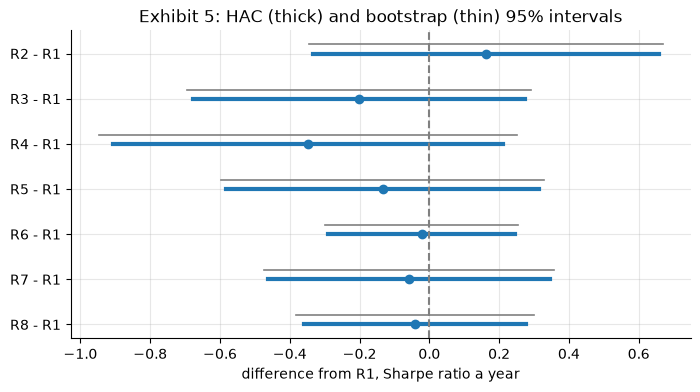

In [9]:
x1, x2 = X[:, 0], X[:, 1]
naive = math.sqrt(SE9["R2"] ** 2 + SE9["R1"] ** 2)
show("independent-samples SE a year", naive * sqA, ".3f", "0.521")
show("correlation R2-R1", float(np.corrcoef(x2, x1)[0, 1]), ".2f", "0.70")
for lg, p in zip((0, 7, 22, 60), ("0.280", "0.253", "0.250", "0.243")):
    show(f"SE of R2 - R1 at lag {lg}", lw_parts(x2, x1, lg)[1] * sqA, ".3f", p)
rng3 = np.random.default_rng([3, SEED])                  # experiment 3, created once
t21 = abs(lw_parts(x2, x1, L)[0] / lw_parts(x2, x1, L)[1])
p_b = {}
for blk in (1, 5, 10, 26, 50, 100):
    ds = lw_boot(X[:, [1, 0]], [(0, 1)], blk, B, rng3)[:, 0]
    p_b[blk] = (int(np.sum(ds >= t21 - 1e-12)) + 1) / (B + 1)
print("experiment 3, bootstrap p-values by block size:", {k: round(v, 2) for k, v in p_b.items()})
show("lowest", min(p_b.values()), ".2f", "0.53")
show("highest", max(p_b.values()), ".2f", "0.56")
show("largest Monte Carlo SE", max(math.sqrt(p * (1 - p) / B) for p in p_b.values()), ".3f", "0.005")
c = res["R2"]["se"] * math.sqrt(tau)
z80 = float(stats.norm.ppf(0.975) + stats.norm.ppf(0.8))
show("years of sessions for 80% power", (z80 * c / res["R2"]["d"]) ** 2, ".0f", "146")
show("one-sided at power 1/2", (Z95 * c / res["R2"]["d"]) ** 2, ".0f", "50")

fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(7, 0, -1)
for yy, k in zip(y, RULES[1:]):
    r = res[k]
    ax.plot([r["d"] - Z975 * r["se"], r["d"] + Z975 * r["se"]], [yy, yy], lw=3, color="C0")
    ax.plot([r["d"] - r["q"] * r["se"], r["d"] + r["q"] * r["se"]], [yy + 0.2, yy + 0.2], lw=1.2, color="grey")
    ax.plot(r["d"], yy, "o", color="C0")
ax.axvline(0, ls="--", color="grey")
ax.set_yticks(y, [f"{k} - R1" for k in RULES[1:]])
ax.set_xlabel("difference from R1, Sharpe ratio a year")
ax.set_title("Exhibit 5: HAC (thick) and bootstrap (thin) 95% intervals")
plt.show()

## Part 7 — The best of eight: (33.4), experiment 2 and DSR

Exhibit 6, Example 8, Bailey and López de Prado's (2014) example and problem 8 (b).

n = 2: exact 0.5642, approximation 0.5198, (21.9)'s median 0.5450
n = 5: exact 1.1630, approximation 1.1926, (21.9)'s median 1.1290
n = 8: exact 1.4236, approximation 1.4590, (21.9)'s median 1.3852
n = 100: exact 2.5076, approximation 2.5306, (21.9)'s median 2.4620
E Z_(8): 1.4236   [book: 1.4236]
problem 4: E Z_(5): 1.163   [book: 1.163]
the deflated benchmark at n = 8, a year: 0.517   [book: 0.517]
DSR at n = 8: 0.955   [book: 0.955]
with the approximation: 0.951   [book: 0.951]
with R2's HAC SE: 0.948   [book: 0.948]
DSR = 0.95 at n: 8.8   [book: 8.8]
mean correlation: 0.821   [book: 0.821]
E max of N_8(0, C): 0.588   [book: 0.588]
its Monte Carlo SE: 0.0009   [book: 0.0009]
n_eff: 2.07   [book: 2.07]
DSR at n_eff: 0.994   [book: 0.994]
eq. (9) of Bailey and Lopez de Prado: 2.25   [book: 2.25]
SD of the eight estimates, a year: 0.141   [book: 0.141]
expected under equal true ratios: 0.144   [book: 0.144]
MinTRL at n = 8 (sessions): 1,796   [book: 1,796]
in years of sessions: 7.37   

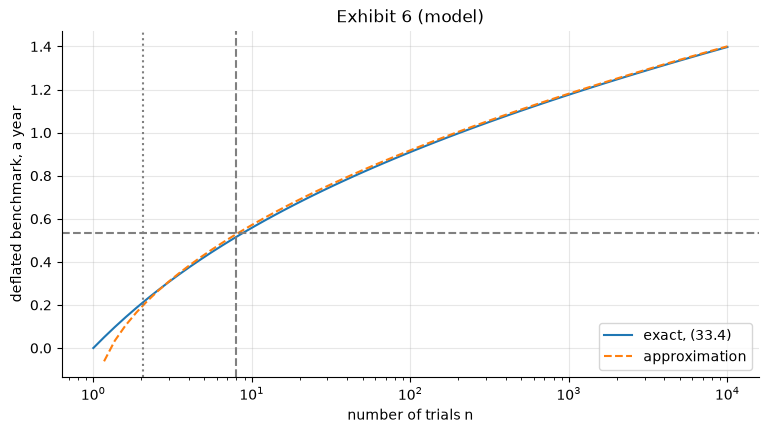

In [10]:
for n in (2, 5, 8, 100):
    print(f"n = {n}: exact {emax(n):.4f}, approximation {emax_bldp(n):.4f}, (21.9)'s median "
          f"{stats.norm.ppf(0.5 ** (1 / n)):.4f}")
ez8 = emax(8)
show("E Z_(8)", ez8, ".4f", "1.4236")
show("problem 4: E Z_(5)", emax(5), ".3f", "1.163")
s0 = 1 / math.sqrt(T - 1)
show("the deflated benchmark at n = 8, a year", ez8 * s0 * sqA, ".3f", "0.517")
show("DSR at n = 8", psr(SR["R2"], ez8 * s0, T, sk2, ku2), ".3f", "0.955")
show("with the approximation", psr(SR["R2"], emax_bldp(8) * s0, T, sk2, ku2), ".3f", "0.951")
show("with R2's HAC SE", float(stats.norm.cdf((SR["R2"] - ez8 * s0) / SEH["R2"])), ".3f", "0.948")
nstar = optimize.brentq(lambda n: psr(SR["R2"], emax(n) * s0, T, sk2, ku2) - 0.95, 2, 100, xtol=1e-10)
show("DSR = 0.95 at n", nstar, ".1f", "8.8")

C = np.corrcoef(X, rowvar=False)
off = C[~np.eye(8, dtype=bool)]
show("mean correlation", float(off.mean()), ".3f", "0.821")
rng2 = np.random.default_rng([2, SEED])                  # experiment 2, created once
mx = (rng2.standard_normal((1_000_000, 8)) @ np.linalg.cholesky(C).T).max(axis=1)
emc, emc_se = float(mx.mean()), float(mx.std() / 1000)
show("E max of N_8(0, C)", emc, ".3f", "0.588")
show("its Monte Carlo SE", emc_se, ".4f", "0.0009")
neff = optimize.brentq(lambda n: emax(n) - emc, 1.000001, 8, xtol=1e-12)
show("n_eff", neff, ".2f", "2.07")
show("DSR at n_eff", psr(SR["R2"], emc * s0, T, sk2, ku2), ".3f", "0.994")
show("eq. (9) of Bailey and Lopez de Prado", float(off.mean()) + (1 - float(off.mean())) * 8, ".2f", "2.25")
cs = float(np.array([SR[k] for k in RULES]).std())
show("SD of the eight estimates, a year", cs * sqA, ".3f", "0.141")
show("expected under equal true ratios", math.sqrt((1 - C.sum() / 64) / T) * sqA, ".3f", "0.144")


def mintrl_n(ez):
    # (33.5) for R2 at 95%
    return 1 + ((Z95 * math.sqrt(v209(SR["R2"], sk2, ku2)) + ez) / SR["R2"]) ** 2


show("MinTRL at n = 8 (sessions)", mintrl_n(ez8), ",.0f", "1,796")
show("in years of sessions", mintrl_n(ez8) / Aw, ".2f", "7.37")
show("at n_eff", mintrl_n(emc) / Aw, ".1f", "3.9")
show("at n = 100", mintrl_n(emax(100)) / Aw, ".1f", "13.5")
sr14, v14 = 2.5 / math.sqrt(250), 0.5 / 250
show("2014 example: threshold a day", math.sqrt(v14) * emax_bldp(100), ".4f", "0.1132")
show("DSR at 100", psr(sr14, math.sqrt(v14) * emax_bldp(100), 1250, -3, 10), ".4f", "0.9004")
show("at 46", psr(sr14, math.sqrt(v14) * emax_bldp(46), 1250, -3, 10), ".4f", "0.9505")
show("normal returns at 88", psr(sr14, math.sqrt(v14) * emax_bldp(88), 1250, 0, 3), ".4f", "0.9505")
n05 = optimize.brentq(lambda n: emax(n) - math.sqrt(0.5 / math.pi), 1.000001, 2, xtol=1e-12)
show("problem 8 (b): the n with E Z_(n) = sqrt(0.5 / pi)", n05, ".3f", "1.608")

ng = np.geomspace(1, 10000, 60)
fig, ax = plt.subplots()
ax.plot(ng, [emax(n) * s0 * sqA for n in ng], label="exact, (33.4)")
ax.plot(ng[1:], [emax_bldp(n) * s0 * sqA for n in ng[1:]], ls="--", label="approximation")
ax.axhline((SR["R2"] - Z95 * math.sqrt(v209(SR["R2"], sk2, ku2) / (T - 1))) * sqA, ls="--", color="grey")
ax.axvline(8, ls="--", color="grey")
ax.axvline(neff, ls=":", color="grey")
ax.set_xscale("log")
ax.set_xlabel("number of trials n")
ax.set_ylabel("deflated benchmark, a year")
ax.set_title("Exhibit 6 (model)")
ax.legend()
plt.show()

## Part 8 — Haircuts

Exhibit 7 and Example 9: (33.7) with $n=8$ on the two-sided normal p-value of $\widehat{\mathrm{SR}}\sqrt T$, and Harvey and Liu's example with the normal and the $t_{239}$ reference.

shape: (8, 5)
┌──────┬──────┬─────────────────┬────────────────┬──────────┐
│ rule ┆ SR   ┆ HSR independent ┆ HSR Bonferroni ┆ HSR Holm │
│ ---  ┆ ---  ┆ ---             ┆ ---            ┆ ---      │
│ str  ┆ f64  ┆ f64             ┆ f64            ┆ f64      │
╞══════╪══════╪═════════════════╪════════════════╪══════════╡
│ R1   ┆ 0.98 ┆ 0.69            ┆ 0.69           ┆ 0.71     │
│ R2   ┆ 1.14 ┆ 0.9             ┆ 0.89           ┆ 0.89     │
│ R3   ┆ 0.77 ┆ 0.43            ┆ 0.41           ┆ 0.67     │
│ R4   ┆ 0.63 ┆ 0.24            ┆ 0.16           ┆ 0.63     │
│ R5   ┆ 0.84 ┆ 0.52            ┆ 0.51           ┆ 0.68     │
│ R6   ┆ 0.95 ┆ 0.67            ┆ 0.66           ┆ 0.71     │
│ R7   ┆ 0.92 ┆ 0.62            ┆ 0.61           ┆ 0.71     │
│ R8   ┆ 0.94 ┆ 0.64            ┆ 0.64           ┆ 0.71     │
└──────┴──────┴─────────────────┴────────────────┴──────────┘
Example 9: R2's t-stat: 3.137   [book: 3.137]
its p-value: 0.00171   [book: 0.00171]
adjusted, independent tests: 0.01

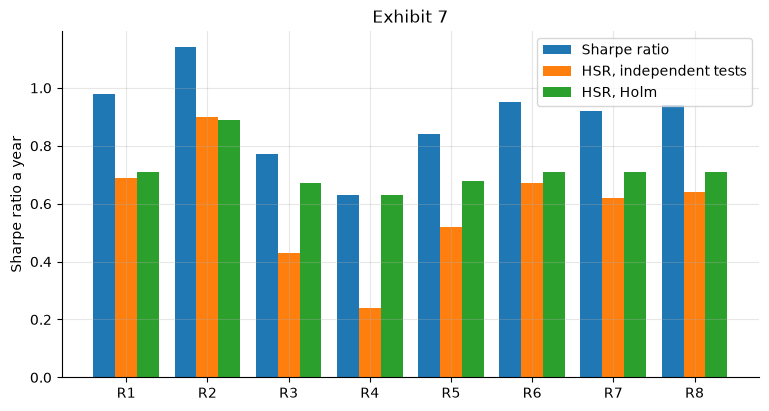

In [11]:
pS = {k: two_sided(SR[k] * math.sqrt(T)) for k in RULES}
hol = dict(zip(RULES, holm([pS[k] for k in RULES])))


def hsr(p_adj):
    return 0.0 if p_adj >= 1 else float(stats.norm.isf(p_adj / 2) / math.sqrt(T) * sqA)


hc = pl.DataFrame({"rule": RULES, "SR": [round(SR[k] * sqA, 2) for k in RULES],
                   "HSR independent": [round(hsr(1 - (1 - pS[k]) ** 8), 2) for k in RULES],
                   "HSR Bonferroni": [round(hsr(min(1, 8 * pS[k])), 2) for k in RULES],
                   "HSR Holm": [round(hsr(hol[k]), 2) for k in RULES]})
print(hc)
show("Example 9: R2's t-stat", SR["R2"] * math.sqrt(T), ".3f", "3.137")
show("its p-value", pS["R2"], ".5f", "0.00171")
show("adjusted, independent tests", 1 - (1 - pS["R2"]) ** 8, ".4f", "0.0136")
show("adjusted, Bonferroni", 8 * pS["R2"], ".4f", "0.0137")
show("t-stat adjusted", float(stats.norm.isf((1 - (1 - pS["R2"]) ** 8) / 2)), ".2f", "2.47")
show("HSR", hsr(1 - (1 - pS["R2"]) ** 8), ".2f", "0.90")
show("haircut (%)", 100 * (1 - hsr(1 - (1 - pS["R2"]) ** 8) / (SR["R2"] * sqA)), ".0f", "21")
show("Bonferroni's HSR", hsr(8 * pS["R2"]), ".2f", "0.89")
show("Bonferroni's haircut (%)", 100 * (1 - hsr(8 * pS["R2"]) / (SR["R2"] * sqA)), ".0f", "21")
show("Holm's HSR of R2", hsr(hol["R2"]), ".2f", "0.89")
show("Holm's HSR of R6", hsr(hol["R6"]), ".2f", "0.71")
show("Bonferroni's haircut of R4 (%)", 100 * (1 - hsr(min(1, 8 * pS["R4"])) / (SR["R4"] * sqA)), ".0f", "75")
t240 = 0.75 / math.sqrt(12) * math.sqrt(240)
pn = two_sided(t240)
show("Harvey and Liu: single p-value, normal", pn, ".4f", "0.0008")
show("adjusted for 200 tests", 1 - (1 - pn) ** 200, ".2f", "0.15")
show("HSR, normal", float(stats.norm.isf((1 - (1 - pn) ** 200) / 2)) / math.sqrt(240) * math.sqrt(12), ".2f", "0.32")
pt = float(2 * stats.t.sf(t240, 239))
show("HSR with t_239", float(stats.t.isf((1 - (1 - pt) ** 200) / 2, 239)) / math.sqrt(240) * math.sqrt(12), ".2f", "0.31")

fig, ax = plt.subplots()
xx = np.arange(8)
ax.bar(xx - 0.27, hc["SR"], 0.27, label="Sharpe ratio")
ax.bar(xx, hc["HSR independent"], 0.27, label="HSR, independent tests")
ax.bar(xx + 0.27, hc["HSR Holm"], 0.27, label="HSR, Holm")
ax.set_xticks(xx, RULES)
ax.set_ylabel("Sharpe ratio a year")
ax.set_title("Exhibit 7")
ax.legend()
plt.show()

## Part 9 — Extension: R2's PSR(0) on rolling windows

A **stability check**, not a result: compute R2's PSR(0) by (33.2) on every window of 730 consecutive sessions (about three years of sessions), and plot it against the window's last date. How often does it fall below 0.95, and when?

Picking a window after seeing this curve would be one more trial on the same data, the kind of search that LM34 corrects.

1122 windows of 730 sessions; PSR(0) from 0.473 to 0.999; below 0.95 in 822 windows


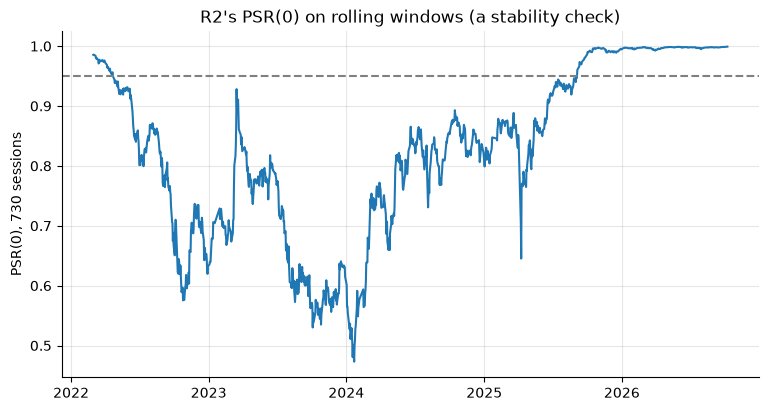

In [12]:
win = 730
ends_w = list(range(win, T + 1))
roll = []
for e in ends_w:
    _, s_, sk_, ku_ = moments(x2[e - win:e])
    roll.append(psr(x2[e - win:e].mean() / s_, 0, win, sk_, ku_))
roll = np.array(roll)
print(f"{len(roll)} windows of {win} sessions; PSR(0) from {roll.min():.3f} to {roll.max():.3f}; "
      f"below 0.95 in {int((roll < 0.95 - 1e-12).sum())} windows")
fig, ax = plt.subplots()
ax.plot([date.fromisoformat(dates[e]) for e in ends_w], roll)
ax.axhline(0.95, ls="--", color="grey")
ax.set_ylabel("PSR(0), 730 sessions")
ax.set_title("R2's PSR(0) on rolling windows (a stability check)")
plt.show()